Variational Autoencoders (VAE)

## 1. First, why do we need VAEs?

A GAN consists of two neural networks:

- **Generator:** Generates fake images.
- **Discriminator:** Determines whether an image is real or fake.

The Generator learns to produce realistic images by trying to fool the Discriminator.

For example, suppose we train a GAN using 10,000 images of human faces.

After training, we can provide random noise to the Generator, and it produces a new human face.

But here's an interesting question:

**What if we want a model that learns a meaningful representation of the images it sees and can generate new images by sampling from that learned representation?**

This is where Variational Autoencoders come in.

A VAE learns a compressed, probabilistic representation of the training data and uses that representation to generate new samples.

## 2. First understand a normal Autoencoder

Before understanding a VAE, we need to understand an Autoencoder.

An Autoencoder is a neural network that learns to compress input data and reconstruct the original input.

It has two main components:

1. Encoder
2. Decoder

Consider that we provide an image of a handwritten digit.

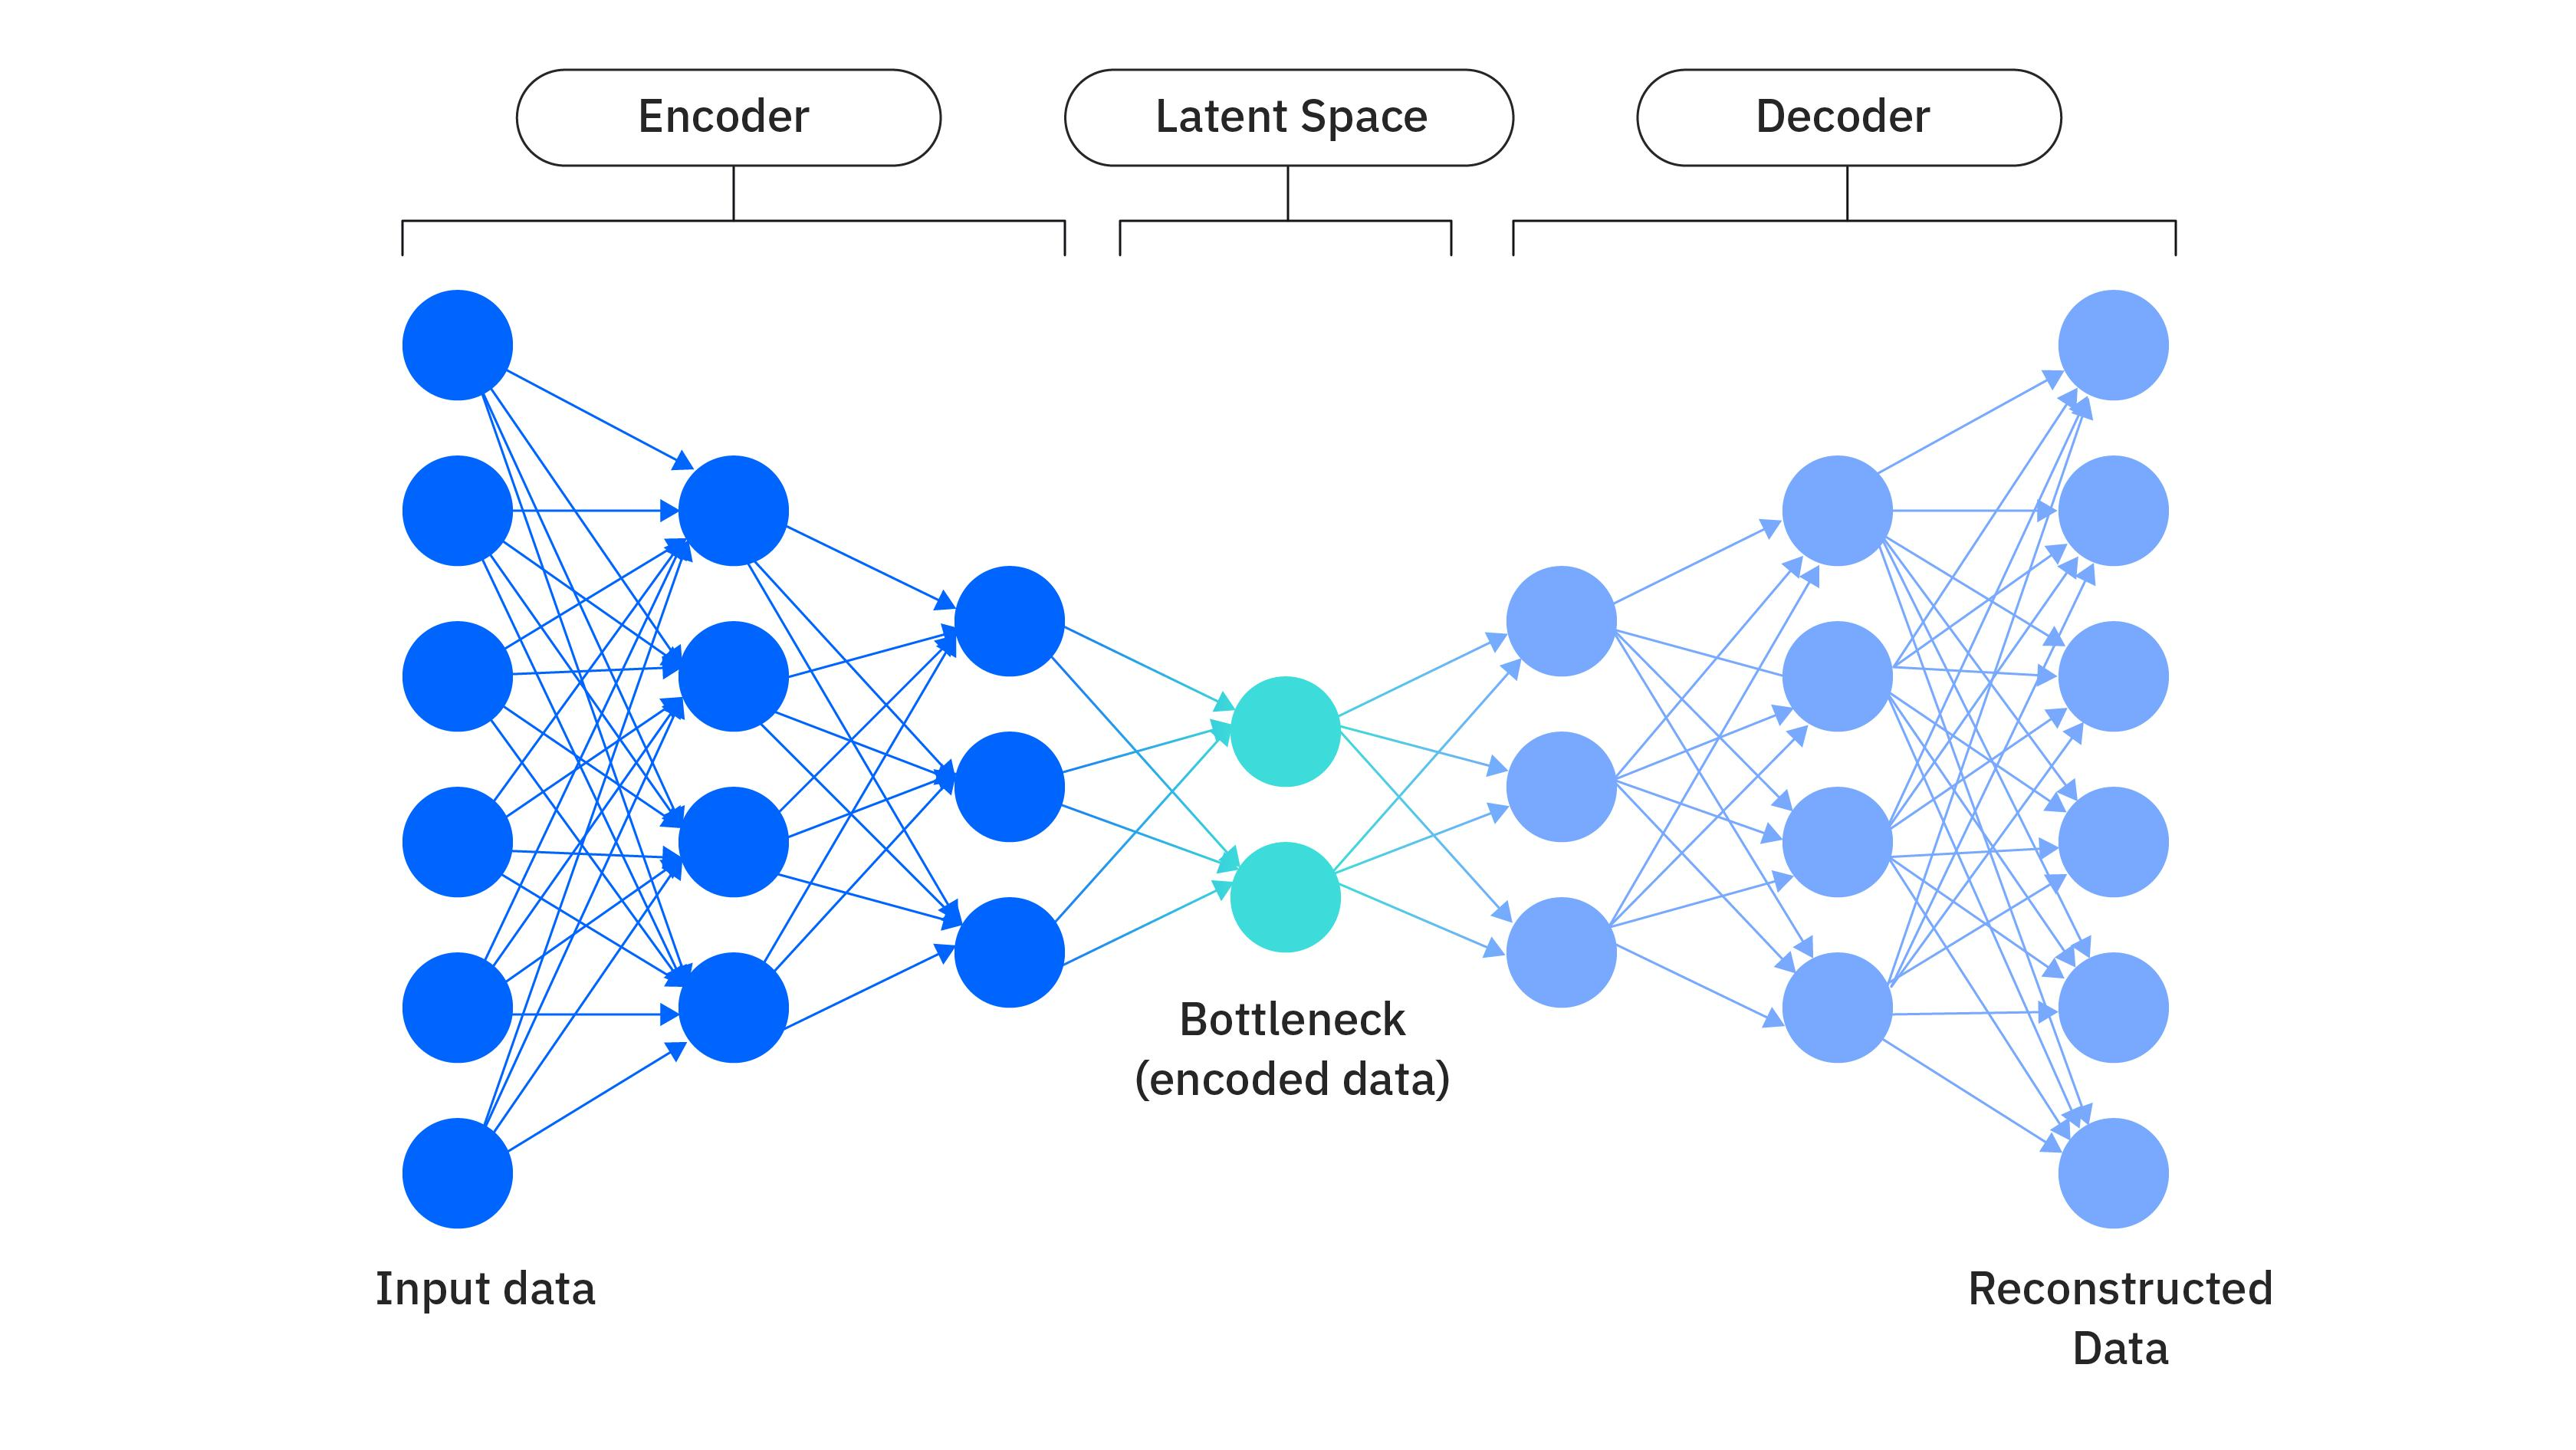

### Encoder

The encoder receives the original image and compresses it into a smaller representation called the latent representation.

For example:

Original image:

28 × 28 pixels = 784 values.

The encoder compresses these 784 values into a vector of 32 values.

Conceptually:

`784 dimensions → 128 → 64 → 32`

The 32-dimensional vector represents the important information learned from the image.

### Decoder

The decoder takes this compressed representation and reconstructs the original image.

Conceptually:

`32 → 64 → 128 → 784`

The reconstructed image should look as similar as possible to the original.

### Why do we do this?

Because we want the neural network to learn meaningful features without explicitly telling it what those features should be.

For example, when learning handwritten digits, it might learn representations related to:

- Curves.
- Edges.
- Shapes.
- Stroke thickness.
- Digit structure.

The network learns these representations through training.

### How does it learn?

We compare:

- Original image.
- Reconstructed image.

The difference between them is called reconstruction loss.

The model updates its weights through backpropagation to reduce this loss.

For example:

| Original | Reconstructed |
|---|---|
| Image of digit 5 | Slightly distorted image of 5 |

The objective is to minimize the reconstruction error.

**Important:** A normal Autoencoder is primarily designed to reconstruct inputs. Its latent space is not necessarily organized in a way that allows us to generate meaningful new samples by randomly sampling vectors.

This is the limitation that motivates VAEs.

---

## 3. What is the problem with a normal Autoencoder?

Imagine our Autoencoder has learned to compress 10,000 handwritten digit images into a 32-dimensional latent space.

Now suppose we randomly generate a 32-dimensional vector and pass it to the decoder.

Will we get a meaningful handwritten digit?

Not necessarily.

Why?

Because the Autoencoder has learned representations corresponding to the training examples, but it has not been explicitly trained to make the latent space follow a known probability distribution.

Some regions of the latent space may contain meaningful representations, while others may contain nothing useful.

This is an important distinction.

We want to generate new samples, not merely reconstruct existing ones.

**This is the problem VAEs address.**

## 4. What is a Variational Autoencoder?

A Variational Autoencoder is a generative neural network that learns a probability distribution over latent representations rather than learning just one fixed latent representation for each input.

Let's compare the two.

| Normal Autoencoder | Variational Autoencoder |
|---|---|
| Encoder produces a latent vector | Encoder produces mean and variance |
| Deterministic latent representation | Probabilistic latent representation |
| No explicit constraint on latent distribution | Regularizes latent distribution |
| Primarily used for reconstruction | Reconstruction and generation |
| Random sampling may produce meaningless outputs | Sampling is designed to produce meaningful outputs |

The important change is in the encoder.

A normal Autoencoder produces a vector.

A VAE produces parameters describing a probability distribution.

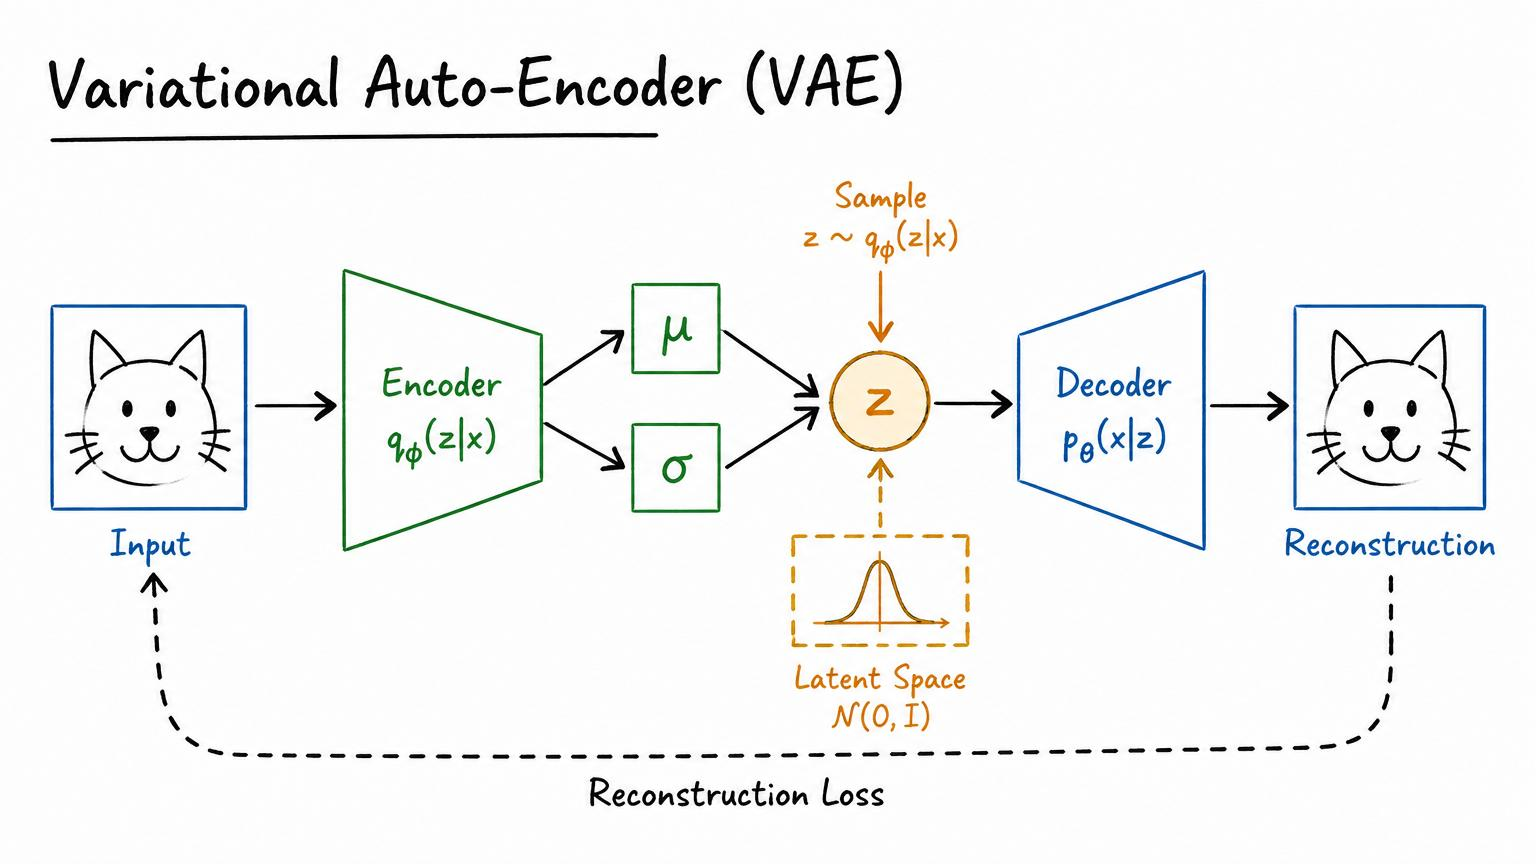

## 5. VAE Architecture

A VAE consists of:

1. Encoder.
2. Latent probability distribution.
3. Sampling operation.
4. Decoder.

Let's follow an image through the network.

### Step 1: Input

We provide an image of a handwritten digit.

For MNIST:

`28 × 28 = 784 values`

### Step 2: Encoder

The encoder processes the image and produces two vectors:

- Mean (μ)
- Variance (σ²)

For example:

```python
mean = [0.5, 0.8, -0.2]

variance = [0.1, 0.2, 0.3]
```

These represent a probability distribution for the latent representation.

The encoder is effectively saying:

"Based on this input image, its latent representation should be somewhere around this mean, with this amount of uncertainty."

This is different from a normal Autoencoder, which directly produces a latent vector.

### Step 3: Sampling

We sample a latent vector from the probability distribution.

For example:

```python
z = [0.52, 0.75, -0.18]
```

This sampled vector is passed to the decoder.

### Step 4: Decoder

The decoder receives the sampled latent vector and reconstructs the image.

```text
Input image
    |
    v
  Encoder
    |
    |-------- Mean (μ)
    |
    |-------- Variance (σ²)
                |
                v
             Sampling
                |
                v
          Latent vector (z)
                |
                v
             Decoder
                |
                v
       Reconstructed image
```

Now we have the basic architecture.

But there is a very important question.

**Why does the encoder produce mean and variance instead of directly producing the latent vector?**

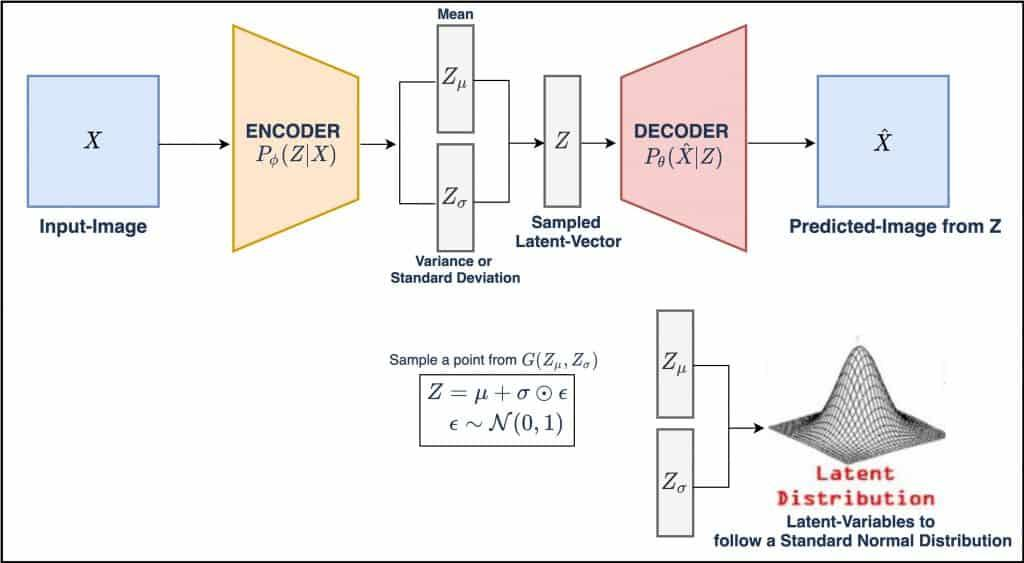

## 6. Understanding Mean and Variance in a VAE

Imagine we are training a VAE on handwritten digits.

We want similar digits to have similar latent representations.

Suppose two images both contain the digit 5.

Their representations should ideally be close to one another in latent space.

Instead of mapping each image to one fixed point, the encoder learns a distribution around a point.

For simplicity, imagine a two-dimensional latent space.

- Mean tells us the centre of the distribution.
- Variance tells us how spread out the distribution is.

For example:

Image A:

```text
Mean = [0.5, 0.8]
Variance = [0.1, 0.2]
```

Image B:

```text
Mean = [0.6, 0.7]
Variance = [0.1, 0.2]
```

Their distributions are close, so sampling from them may produce similar latent representations.

This encourages a smoother latent space.

**Remember:**

- Mean determines the centre.
- Variance determines the spread.
- Sampling produces the actual latent vector.

One technical detail: implementations generally predict log-variance rather than variance directly because it is numerically more convenient and ensures a positive variance after exponentiation.

---

## 7. The Reparameterization Trick

This is one of the most important concepts in VAE.

We have a problem.

The encoder produces mean and variance, and we want to sample a latent vector.

But random sampling is not a normal differentiable operation.

We need to train the encoder using backpropagation.

How can gradients flow through a sampling operation?

This is where the reparameterization trick comes in.

Instead of directly sampling from the learned distribution, we express sampling as a deterministic transformation of the learned parameters and an independent random variable.

The equation is:

\[
z = \mu + \sigma \odot \epsilon
\]

Where:

- \(z\) = sampled latent vector.
- \(\mu\) = mean.
- \(\sigma\) = standard deviation.
- \(\epsilon\) = random noise sampled from a standard normal distribution.
- \(\odot\) = element-wise multiplication.

Let's use an example.

Suppose:

```python
mean = 2.0
std = 0.5

epsilon = 0.4
```

Then:

\[
z = 2.0 + (0.5 \times 0.4)
\]

\[
z = 2.2
\]

The random noise is independent of the encoder's parameters.

Therefore, gradients can flow through the mean and standard deviation.

This allows the encoder to learn through backpropagation.

### Python implementation

```python
import torch

def reparameterize(mean, log_variance):

    std = torch.exp(0.5 * log_variance)

    epsilon = torch.randn_like(std)

    z = mean + std * epsilon

    return z
```

Notice that we use `log_variance` rather than directly passing variance.

The standard deviation is calculated as:

\[
\sigma = e^{\frac{1}{2}\log(\sigma^2)}
\]

This gives us a differentiable sampling mechanism.

---

## 8. VAE Loss Function

Now we understand the architecture.

But how does a VAE learn?

Unlike a normal Autoencoder, a VAE uses two loss components.

### A. Reconstruction Loss

This measures how accurately the decoder reconstructs the original input.

For example:

Original image = handwritten 5.

Reconstructed image = slightly distorted 5.

The reconstruction loss measures their difference.

Common choices include:

- Binary Cross Entropy.
- Mean Squared Error.

The objective is to reconstruct the original input as accurately as possible.

### B. KL Divergence Loss

This is the additional component that makes a VAE different from a normal Autoencoder.

Remember that the encoder produces a probability distribution.

We want the learned latent distributions to remain close to a standard normal distribution.

Why?

Because we want a well-organized latent space from which we can sample new representations.

KL divergence measures the difference between two probability distributions.

In a standard VAE:

- Learned distribution: \(q(z|x)\)
- Prior distribution: \(p(z)\), usually a standard normal distribution.

The KL divergence encourages the learned distribution to remain close to the prior.

### Total VAE Loss

\[
L = L_{\text{reconstruction}} +
D_{KL}(q(z|x)\parallel p(z))
\]

The two objectives work together:

| Loss | Purpose |
|---|---|
| Reconstruction loss | Reconstruct the input accurately |
| KL divergence | Regularize the latent distribution |

If we only optimize reconstruction loss, the model might learn representations that don't form a useful distribution for generation.

If we only optimize KL divergence, the model could ignore the input and produce uninformative representations.

We need both.

---

## 9. How does a VAE generate a completely new image?

This is where everything comes together.

Suppose we have trained our VAE on 10,000 handwritten digit images.

During training:

1. Images are passed through the encoder.
2. Encoder predicts mean and variance.
3. Latent vectors are sampled.
4. Decoder reconstructs the images.
5. Reconstruction and KL losses are calculated.
6. Model weights are updated.

After training, we can generate new images without providing an original image.

How?

1. Sample a random vector from the prior distribution, usually a standard normal distribution.
2. Pass that vector directly to the decoder.
3. Decoder generates a new image.

```python
z = torch.randn(1, latent_dim)

generated_image = decoder(z)
```

That's it!

The encoder is not needed during generation.

This is a critical distinction.

During training:

`Image → Encoder → Sampling → Decoder → Reconstruction`

During generation:

`Random latent vector → Decoder → New image`

---

# 10. Complete VAE vs Autoencoder vs GAN

Let's consolidate what we learned.

| Feature | Autoencoder | VAE | GAN |
|---|---|---|---|
| Main objective | Reconstruction | Reconstruction + distribution regularization | Realistic generation |
| Architecture | Encoder + Decoder | Encoder + probabilistic Decoder | Generator + Discriminator |
| Latent representation | Fixed vector | Probability distribution | Random input noise |
| Sampling | Not explicitly regularized | From learned prior | From input noise distribution |
| Training | Reconstruction loss | Reconstruction + KL divergence | Adversarial loss |
| Main challenge | Unstructured latent space | Reconstruction-quality trade-off | Training instability and mode collapse |

One nuance: GANs also learn a mapping from a noise distribution to generated samples. They don't require an encoder in their basic form.

---

# 11. Interview-ready explanation

If someone asks you, "What is a Variational Autoencoder?", you can answer:

"A Variational Autoencoder is a generative deep learning architecture that learns a probabilistic representation of input data in a latent space. Unlike a traditional Autoencoder, which maps an input to a fixed latent vector, a VAE's encoder predicts the mean and variance of a probability distribution. We sample a latent vector using the reparameterization trick and pass it through the decoder to reconstruct the input. The model is trained using two loss components: reconstruction loss, which ensures accurate reconstruction, and KL divergence, which regularizes the latent distribution towards a prior, typically a standard normal distribution. After training, we can sample from this prior and generate entirely new data."